## K-Means Task

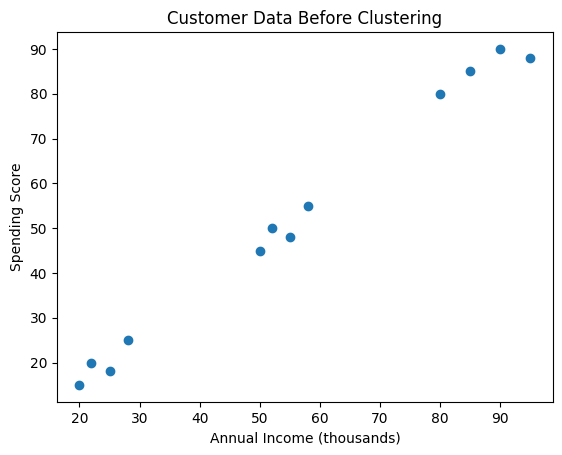

    annual_income  spending_score  cluster_num
0              20              15            0
1              22              20            0
2              25              18            0
3              28              25            0
4              50              45            0
5              52              50            0
6              55              48            0
7              58              55            0
8              80              80            1
9              85              85            1
10             90              90            1
11             95              88            1
   annual_income  spending_score
0          38.75           34.50
1          87.50           85.75


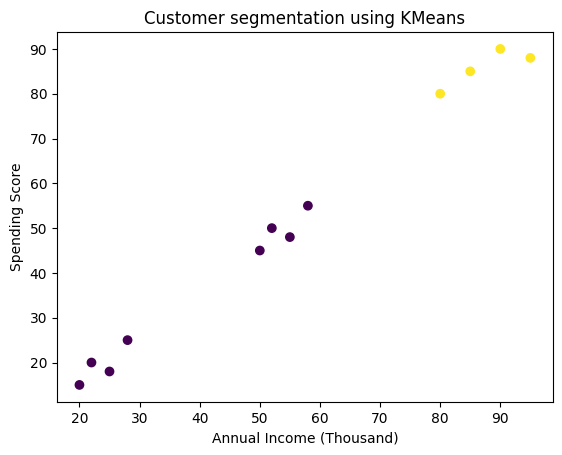

    annual_income  spending_score  cluster_num
0              20              15            2
1              22              20            2
2              25              18            2
3              28              25            2
4              50              45            0
5              52              50            0
6              55              48            0
7              58              55            0
8              80              80            1
9              85              85            1
10             90              90            1
11             95              88            1
   annual_income  spending_score
0          53.75           49.50
1          87.50           85.75
2          23.75           19.50


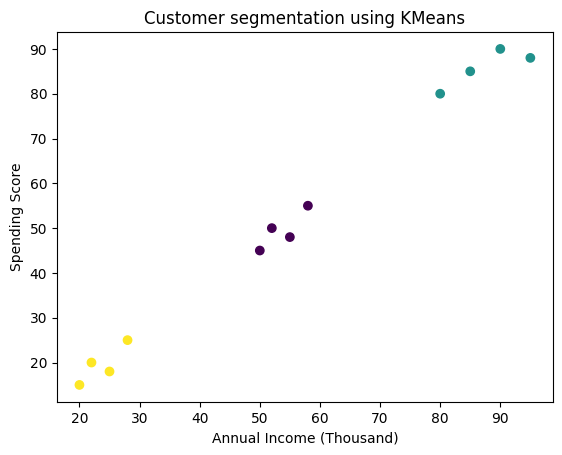

    annual_income  spending_score  cluster_num
0              20              15            2
1              22              20            2
2              25              18            2
3              28              25            2
4              50              45            0
5              52              50            0
6              55              48            0
7              58              55            0
8              80              80            3
9              85              85            3
10             90              90            1
11             95              88            1
   annual_income  spending_score
0          53.75            49.5
1          92.50            89.0
2          23.75            19.5
3          82.50            82.5


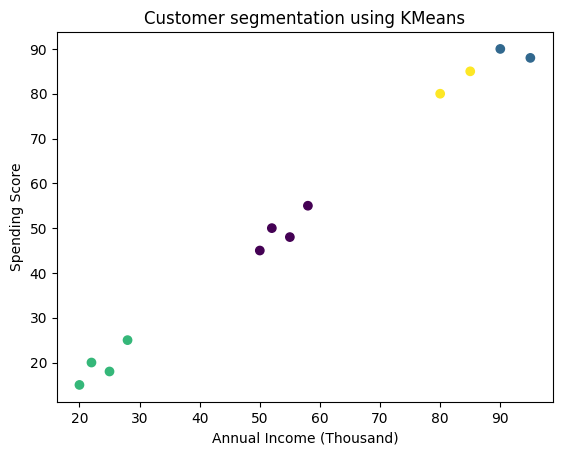

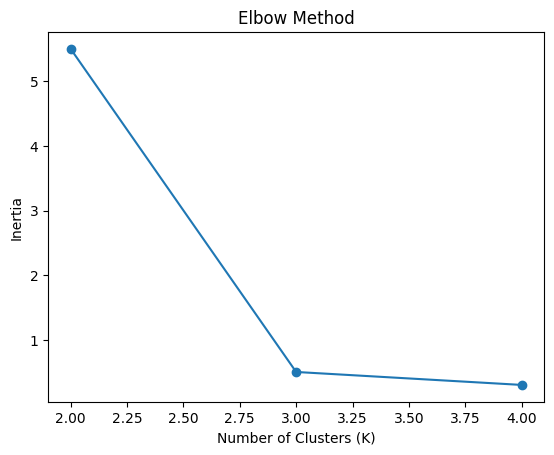

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

df= pd.DataFrame({
     "annual_income": [
        20, 22, 25, 28,
        50, 52, 55, 58,
        80, 85, 90, 95
    ],
    "spending_score": [
        15, 20, 18, 25,
        45, 50, 48, 55,
        80, 85, 90, 88
    ]
})
plt.scatter(
    df["annual_income"],
    df["spending_score"]
)
plt.xlabel("Annual Income (thousands)")
plt.ylabel("Spending Score")
plt.title("Customer Data Before Clustering")
plt.show()

scaler= StandardScaler()
X_scaled=scaler.fit_transform(df)
inertias=[]
k_values=[2,3,4]
for k in k_values:
    model=KMeans(
        n_clusters=k,
        n_init=5,
        random_state=42
    )
    model.fit(X_scaled)
    df["cluster_num"]=model.labels_
    print(df)
    inertias.append(model.inertia_)
    centers=scaler.inverse_transform(model.cluster_centers_)
    cluster_df=pd.DataFrame(
        centers,
        columns=["annual_income", "spending_score"]
    )
    print(cluster_df)
    plt.scatter(df["annual_income"], df["spending_score"], c=df["cluster_num"])
    plt.title("Customer segmentation using KMeans")
    plt.xlabel("Annual Income (Thousand)")
    plt.ylabel("Spending Score")
    plt.show()

plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

## Practice: Single K value

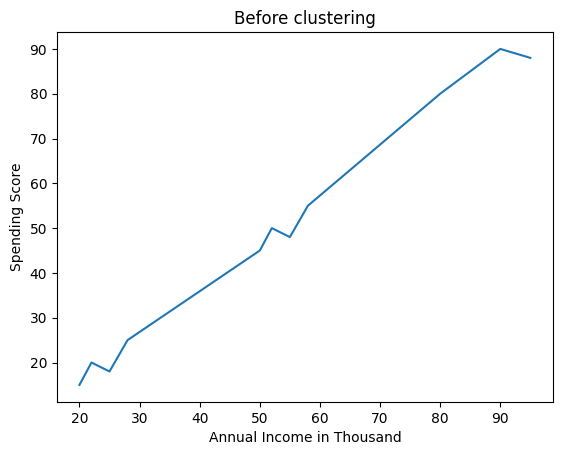

   annual_income  spending_score  cluster
0             30              12        2
1             22              10        2
2             34              22        0
3             52              34        0
4             10               8        2
5             11              11        2
6             39              32        0
7             63              55        1


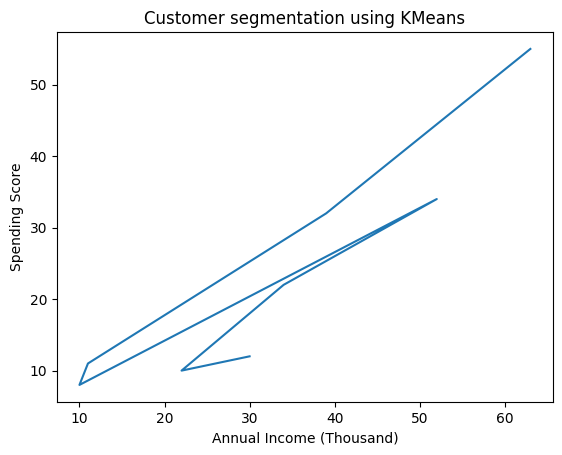

In [8]:
datas={
    "annual_income":[30, 22, 34, 52, 10, 11, 39, 63],
    "spending_score":[12, 10, 22, 34, 8, 11, 32, 55]
}
dataframe= pd.DataFrame(datas)
plt.plot(df["annual_income"], df["spending_score"])
plt.xlabel("Annual Income in Thousand")
plt.ylabel("Spending Score")
plt.title("Before clustering")
plt.show()
scale=StandardScaler()
X_scale=scale.fit_transform(dataframe)
p_model=KMeans( #p_model=practice model
    n_clusters=3,
    random_state=42,
    n_init=10
)
p_model.fit(X_scale)
dataframe["cluster"]=p_model.labels_
print(dataframe)

p_centers=scale.inverse_transform(p_model.cluster_centers_)
p_cluster_df=pd.DataFrame(
    p_centers,
    columns=["annual_income", "spending_score"]
)
plt.plot(dataframe["annual_income"], dataframe["spending_score"])
plt.title("Customer segmentation using KMeans")
plt.xlabel("Annual Income (Thousand)")
plt.ylabel("Spending Score")
plt.show()

## Practice: Elbow Method

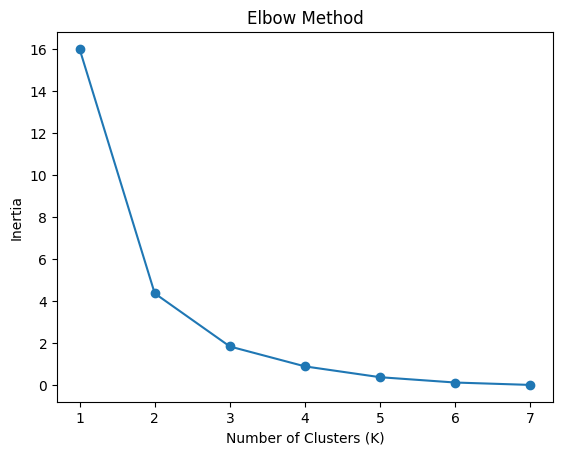

In [9]:
inertiae=[]
k_val=range(1,8)
for k in k_val:
    p_model=KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    p_model.fit(X_scale)
    inertiae.append(p_model.inertia_)
plt.plot(k_val, inertiae, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show() 